# Valuing a start-up that has no revenue yet

*Companion notebook to Chapter 4 of the thesis "Company Valuation Using the Discounted Cash Flow Method and Monte Carlo Simulation" (Milan Stamenović, 2026).*

**The question:** what is a young software company worth if it has a product prototype and two founders, but no customers and no revenue yet?

**The company:** TPTM Solutions builds cloud software that automates transfer pricing documentation for tax consulting firms. The valuation date is May 2026. Every number below is a *plan*, not a fact.

**The approach, in plain words:**

1. Estimate how much cash the business will produce each year (the **free cash flow**).
2. Decide how much less a euro received in the future is worth than a euro today. This **discount rate** depends on how risky the business is.
3. Add up the discounted cash flows. That gives the value of the business today. This is the **discounted cash flow (DCF)** method.
4. Since nobody knows the future, repeat the calculation 100,000 times with randomly varied assumptions (**Monte Carlo simulation**). The result is a range of possible values rather than one number.

In [1]:
# Make the package importable when it is not installed (pip install -e .)
import sys
from pathlib import Path

try:
    import dcf_valuation  # noqa: F401
except ImportError:
    sys.path.insert(0, str(Path.cwd().parent / "src"))

import matplotlib.pyplot as plt
from IPython.display import Markdown, display

import dcf_valuation as dv
from dcf_valuation import plots
from dcf_valuation.analysis import LABELS
from dcf_valuation.thesis import run_model

EXAMPLES = Path.cwd().parent / "examples"


def table(header, rows):
    """Show a small table as Markdown."""
    lines = ["| " + " | ".join(header) + " |", "|" + "---|" * len(header)]
    lines += ["| " + " | ".join(str(c) for c in r) + " |" for r in rows]
    display(Markdown("\n".join(lines)))


def eur(x):
    return f"{x:,.0f}"


def show(fig):
    """Display a chart in the notebook."""
    display(fig)
    plt.close(fig)

## 1. The inputs

All assumptions live in one readable file, `examples/startup.yaml`. Each number in it comes from a table in the thesis.

In [2]:
cfg = dv.load_config(EXAMPLES / "startup.yaml")
p = cfg.projection
table(
    ["", *map(str, p.years)],
    [
        ["Revenue", *map(eur, p.revenue)],
        ["Variable costs (cloud, AI services)", *map(eur, p.variable_costs)],
        ["Fixed costs (salaries, marketing, other)", *map(eur, p.fixed_costs)],
        ["Investment in the platform (capex)", *map(eur, p.capex)],
    ],
)

|  | 2027 | 2028 | 2029 | 2030 | 2031 |
|---|---|---|---|---|---|
| Revenue | 33,984 | 166,233 | 371,714 | 617,694 | 960,325 |
| Variable costs (cloud, AI services) | 16,765 | 13,029 | 14,667 | 16,017 | 21,429 |
| Fixed costs (salaries, marketing, other) | 60,439 | 84,271 | 169,675 | 189,887 | 208,266 |
| Investment in the platform (capex) | 3,000 | 120,000 | 5,000 | 6,000 | 7,000 |

Revenue is planned to grow from about EUR 34 thousand in 2027 to EUR 960 thousand in 2031 as the number of client firms rises from 10 to about 200. Most costs are **fixed**: the founders' salaries don't fall if fewer clients sign up. That makes the plan very sensitive to how fast customers actually arrive.

## 2. The discount rate: how risky is this business?

An investor who puts money into a risky start-up expects a much higher return than one who buys a government bond. That expected return is the **cost of capital**. It is built up from parts:

* a **risk-free rate**: what a German government bond pays (3.11 %);
* a **market risk premium**: the extra return investors demand for owning shares at all (4.23 %), plus a premium for **country risk** in Serbia (3.90 %);
* **beta** (1.23): how much more volatile software companies are than the market as a whole;
* a **specific risk premium** (11 %) for being tiny, pre-revenue and dependent on two people.

In [3]:
w = dv.compute_wacc(cfg.cost_of_capital, cfg.tax_rate)
c = cfg.cost_of_capital
market = w.levered_beta * (c.equity_risk_premium + c.country_risk_premium)
table(
    ["Component", "Value"],
    [
        ["Risk-free rate", f"{c.risk_free_rate:.2%}"],
        [
            "Beta x (market premium + country premium)",
            f"{w.levered_beta:.2f} x ({c.equity_risk_premium:.2%} + {c.country_risk_premium:.2%}) = {market:.2%}",
        ],
        *[[f"Specific risk: {k.replace('_', ' ')}", f"{v:+.1%}"] for k, v in c.specific_risk_components.items()],
        ["**Cost of capital (WACC)**", f"**{w.wacc:.2%}**"],
    ],
)

| Component | Value |
|---|---|
| Risk-free rate | 3.11% |
| Beta x (market premium + country premium) | 1.23 x (4.23% + 3.90%) = 10.00% |
| Specific risk: pre revenue status | +7.0% |
| Specific risk: key person risk | +1.5% |
| Specific risk: niche market | +2.0% |
| Specific risk: technology dependence | +1.5% |
| Specific risk: product stickiness | -1.0% |
| **Cost of capital (WACC)** | **24.11%** |

A discount rate of 24 % means that a euro expected five years from now is worth only about 34 cents today. The company has no debt, so the cost of capital equals the return its owners require.

## 3. Free cash flow: the cash the business generates

Profit is not the same as cash. Free cash flow to the firm (FCFF) is:

> **FCFF = operating profit after tax + depreciation − investment − increase in working capital**

Here, working capital actually *releases* cash, because clients pay their subscriptions a year in advance.

In [4]:
bc = dv.base_case(cfg)
pr = bc.projection
table(
    ["", *map(str, p.years)],
    [
        ["Operating profit (EBIT)", *map(eur, pr.ebit[0])],
        ["Tax at 15 %", *map(eur, pr.nopat[0] - pr.ebit[0])],
        ["+ Depreciation", *map(eur, pr.depreciation[0])],
        ["− Investment (capex)", *map(eur, -pr.capex[0])],
        ["+ Cash from working capital", *map(eur, -pr.nwc_investment[0])],
        ["**Free cash flow**", *[f"**{eur(x)}**" for x in pr.fcf[0]]],
    ],
)

|  | 2027 | 2028 | 2029 | 2030 | 2031 |
|---|---|---|---|---|---|
| Operating profit (EBIT) | -44,053 | 48,100 | 165,705 | 389,123 | 706,797 |
| Tax at 15 % | 6,608 | -7,215 | -24,856 | -58,368 | -106,019 |
| + Depreciation | 833 | 20,833 | 21,667 | 22,667 | 23,833 |
| − Investment (capex) | -3,000 | -120,000 | -5,000 | -6,000 | -7,000 |
| + Cash from working capital | 4,342 | 16,450 | 26,172 | 31,280 | 43,861 |
| **Free cash flow** | **-35,270** | **-41,832** | **183,688** | **378,702** | **661,471** |

The first two years burn cash. In 2028 the company invests EUR 120 thousand in the platform. From 2029 on it generates a lot of cash, if the plan holds.

## 4. Bringing future cash back to today

Each year's cash flow is divided by (1 + 24.1 %) raised to the number of years until it arrives. Cash arrives throughout the year, so the thesis counts it as arriving mid-year (exponents 0.5, 1.5, …).

The company does not stop existing in 2031. Everything after that year is summarised in a **terminal value**, which assumes the cash flow then grows by 2 % a year forever.

| Step | EUR |
|---|---|
| Present value of the cash flows 2027-2031 | 473,202 |
| Terminal value (in 2031 money) | 3,084,835 |
| Present value of the terminal value | 940,365 |
| **Enterprise value** (the operating business) | **1,413,568** |
| + cash at the end of 2026 | 43,486 |
| **Equity value** (what the owners hold) | **1,457,054** |

The terminal value is 66.5% of the enterprise value.


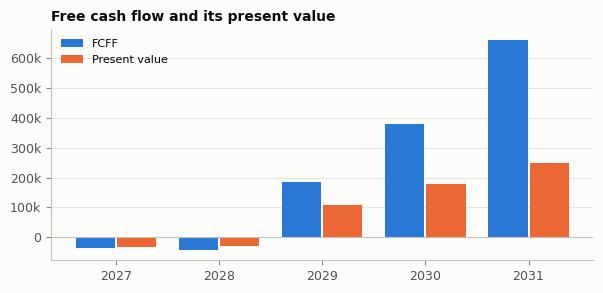

In [5]:
v = bc.valuation
table(
    ["Step", "EUR"],
    [
        ["Present value of the cash flows 2027-2031", eur(v.pv_fcf[0])],
        ["Terminal value (in 2031 money)", eur(v.terminal_value[0])],
        ["Present value of the terminal value", eur(v.pv_terminal_value[0])],
        ["**Enterprise value** (the operating business)", f"**{eur(v.enterprise_value[0])}**"],
        ["+ cash at the end of 2026", eur(cfg.bridge["cash_end_2026"])],
        ["**Equity value** (what the owners hold)", f"**{eur(bc.equity_value)}**"],
    ],
)
print(f"The terminal value is {v.tv_share[0]:.1%} of the enterprise value.")
show(plots.fcf_chart(p.years, pr.fcf[0], v.pv_by_year[0], "Free cash flow and its present value"))

**The base case: about EUR 1.46 million.** This matches Table 6 of the thesis to the euro. Two thirds of the value comes from the years after 2031, which is typical for young companies.

## 5. What if the discount rate or the long-term growth is different?

The table below recomputes the value for every combination of these two hard-to-estimate inputs.

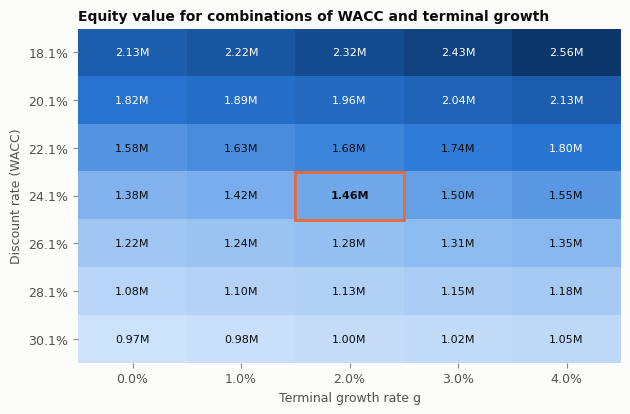

In [6]:
s = cfg.sensitivity
grid = dv.sensitivity_grid(cfg, s.wacc, s.terminal_growth)
show(
    plots.heatmap(
        grid,
        s.wacc,
        s.terminal_growth,
        "Equity value for combinations of WACC and terminal growth",
        base=(w.wacc, cfg.terminal.growth),
    )
)

The discount rate matters much more than long-term growth. At 24 %, cash flows from far in the future count for very little, so the difference between growing at 1 % and at 3 % forever hardly shows up.

## 6. Monte Carlo: many possible futures instead of one

The table above varies only valuation parameters. For a start-up the real uncertainty is in the business itself. The simulation draws four inputs at random (thesis Table 8):

| Input | How it varies |
|---|---|
| Revenue vs the plan | normal, ±10 % per year, **compounding**: a bad first year is followed by more bad years |
| Fixed costs vs the plan | normal, ±10 % |
| Discount rate | normal around 24.1 %, ±2.5 points, kept between 15 % and 35 % |
| Long-term growth | triangular between 1 % and 3 %, most likely 2 % |

The model is then recalculated 100,000 times, all at once with NumPy arrays. With the thesis seed (20260927) the results match Table 9 exactly.

| Statistic | Equity value (EUR) |
|---|---|
| Base case | 1,457,054 |
| Mean | 1,674,382 |
| Median | 1,467,570 |
| 5th percentile | 304,751 |
| 95th percentile | 3,757,977 |
| Coefficient of variation (std / mean) | 0.66 |
| Probability the value is below EUR 500,000 | 10.1% |
| Probability the value exceeds EUR 2,000,000 | 31.1% |

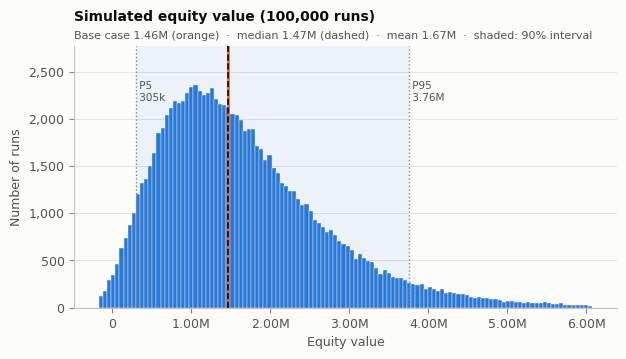

In [7]:
run = run_model(cfg)  # base case + 100,000 simulations + sensitivities
st = run.stats
table(
    ["Statistic", "Equity value (EUR)"],
    [
        ["Base case", eur(st["base"])],
        ["Mean", eur(st["mean"])],
        ["Median", eur(st["p50"])],
        ["5th percentile", eur(st["p5"])],
        ["95th percentile", eur(st["p95"])],
        ["Coefficient of variation (std / mean)", f"{st['cv']:.2f}"],
        ["Probability the value is below EUR 500,000", f"{st['p_below_500000']:.1%}"],
        ["Probability the value exceeds EUR 2,000,000", f"{st['p_above_2000000']:.1%}"],
    ],
)
show(plots.histogram(run.simulation.equity_value, st["base"], "Simulated equity value (100,000 runs)"))

**How to read this:** the median (EUR 1.47 million) is about the same as the base case, but the spread is huge. There is a 90 % chance that the value lies between **EUR 0.30 million and EUR 3.76 million**. The upper end is more than twelve times the lower one. The distribution is skewed to the right: a few very successful futures pull the average (EUR 1.67 million) above the median.

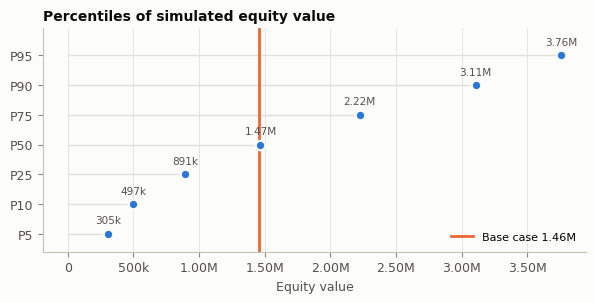

In [8]:
show(plots.percentiles(run.simulation.equity_value, st["base"], "Percentiles of simulated equity value"))

## 7. What drives the value?

The **tornado chart** moves one input at a time from its 10th to its 90th percentile and keeps all the others at the plan. The longest bar is the input that matters most.

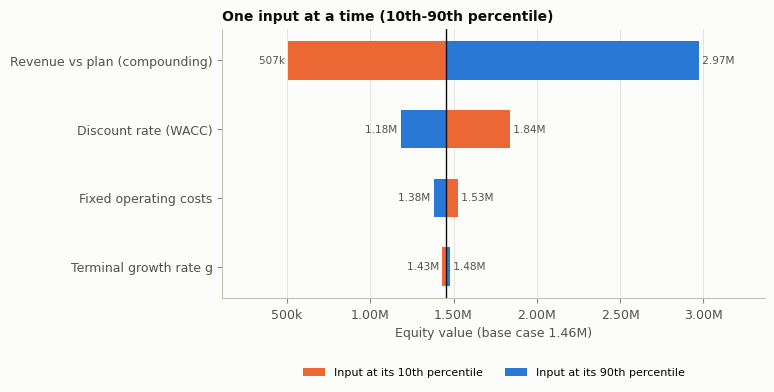

| Input | Rank correlation with value |
|---|---|
| Revenue vs plan (compounding) | +0.96 |
| Discount rate (WACC) | -0.24 |
| Fixed operating costs | -0.06 |
| Terminal growth rate g | +0.02 |

In [9]:
show(plots.tornado_chart(run.tornado, st["base"], "One input at a time (10th-90th percentile)"))
table(
    ["Input", "Rank correlation with value"],
    [[LABELS[k], f"{r:+.2f}"] for k, r in sorted(run.spearman.items(), key=lambda kv: -abs(kv[1]))],
)

Revenue dominates (rank correlation +0.96). If clients arrive 13 % slower than planned each year, the company is worth about EUR 0.5 million; if they arrive 13 % faster, about EUR 3 million. The cost base, which founders tend to worry about most, matters much less.

## 8. Takeaways

* The **base case of EUR 1.46 million** is not wrong, but alone it says little. It is the middle of a very wide range.
* A DCF of a pre-revenue company values a **story**. The simulation shows how much of the value depends on that story coming true.
* The one thing that would narrow the range is **evidence about customer adoption**. That means winning the first clients.

To check every number against the thesis, run `python scripts/reproduce_thesis.py`.